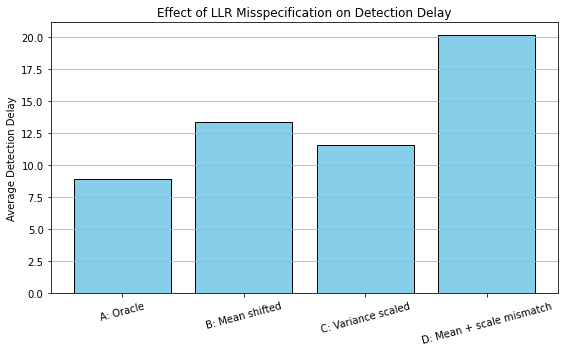

In [2]:
# Re-run after kernel reset
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.stats import norm
import sys
sys.path.append('../scripts')
from OracleCUSUM import CUSUM

# Define mismatched LLR cases
def make_llr_pdfs(case, delta):
    if case == 'A':  # Oracle
        return lambda x: norm.pdf(x, 0, 1), lambda x: norm.pdf(x, delta, 1)
    elif case == 'B':  # Mean shifted
        return lambda x: norm.pdf(x, 0.2, 1), lambda x: norm.pdf(x, delta + 0.2, 1)
    elif case == 'C':  # Variance scaled
        return lambda x: norm.pdf(x, 0, 1.2), lambda x: norm.pdf(x, delta, 0.8)
    elif case == 'D':  # Mean + variance mismatch
        return lambda x: norm.pdf(x, 0.3, 1.1), lambda x: norm.pdf(x, delta + 0.3, 0.9)
    else:
        raise ValueError("Unknown mismatch case")

# Run detection delay experiment for each mismatch
def evaluate_mismatch_cases(delta=1.0, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    results = {}

    for case in ['A', 'B', 'C', 'D']:
        f0_m, f1_m = make_llr_pdfs(case, delta)
        detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)

        delays = []
        for _ in range(num_trials):
            stream = np.concatenate([
                np.random.normal(0, 1, changepoint),
                np.random.normal(delta, 1, stream_length - changepoint)
            ])
            _, _, tau = detector.run(stream)
            if tau is not None and tau > changepoint:
                delays.append(tau - changepoint)

        avg_delay = np.mean(delays) if delays else np.nan
        results[case] = avg_delay

    return results

# Run and display results
mismatch_results = evaluate_mismatch_cases()

# Plotting
cases = ['A', 'B', 'C', 'D']
delays = [mismatch_results[c] for c in cases]
labels = [
    'A: Oracle',
    'B: Mean shifted',
    'C: Variance scaled',
    'D: Mean + scale mismatch'
]

plt.figure(figsize=(8, 5))
plt.bar(cases, delays, tick_label=labels, color='skyblue', edgecolor='black')
plt.ylabel("Average Detection Delay")
plt.title("Effect of LLR Misspecification on Detection Delay")
plt.xticks(rotation=15)
plt.grid(True, axis='y')
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/LLR_misspec_effects.png", dpi=300, bbox_inches='tight')
plt.show()

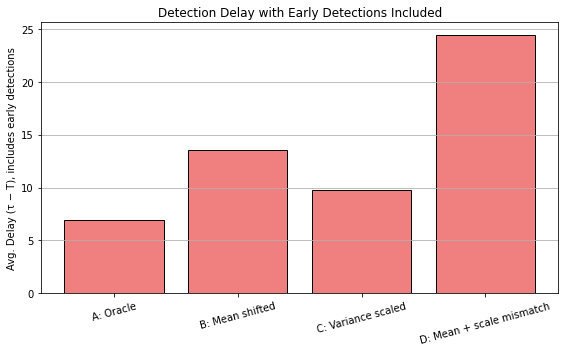

In [3]:
def evaluate_mismatch_all_cases(delta=1.0, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    results = {}

    for case in ['A', 'B', 'C', 'D']:
        f0_m, f1_m = make_llr_pdfs(case, delta)
        detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)

        delays = []
        for _ in range(num_trials):
            stream = np.concatenate([
                np.random.normal(0, 1, changepoint),
                np.random.normal(delta, 1, stream_length - changepoint)
            ])
            _, _, tau = detector.run(stream)
            if tau is not None:
                delays.append(tau - changepoint)  # may be negative if early

        avg_delay = np.mean(delays) if delays else np.nan
        results[case] = avg_delay

    return results

mismatch_all_results = evaluate_mismatch_all_cases()

cases = ['A', 'B', 'C', 'D']
delays_all = [mismatch_all_results[c] for c in cases]
labels = [
    'A: Oracle',
    'B: Mean shifted',
    'C: Variance scaled',
    'D: Mean + scale mismatch'
]

plt.figure(figsize=(8, 5))
plt.bar(cases, delays_all, tick_label=labels, color='lightcoral', edgecolor='black')
plt.ylabel("Avg. Delay (τ − T), includes early detections")
plt.title("Detection Delay with Early Detections Included")
plt.xticks(rotation=15)
plt.grid(True, axis='y')
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/LLR_misspec_effects_neg_DD.png", dpi=300, bbox_inches='tight')
plt.show()


In [4]:
import seaborn as sns

def evaluate_and_plot_histogram(case, delta=1.0, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    f0_m, f1_m = make_llr_pdfs(case, delta)
    detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)

    delays = []
    for _ in range(num_trials):
        stream = np.concatenate([
            np.random.normal(0, 1, changepoint),
            np.random.normal(delta, 1, stream_length - changepoint)
        ])
        _, _, tau = detector.run(stream)
        if tau is not None:
            delays.append(tau - changepoint)

    print(f"{case} - Mean: {np.mean(delays):.2f}, Min: {np.min(delays)}, Max: {np.max(delays)}")
    sns.histplot(delays, bins=30, kde=True)
    plt.title(f"Histogram of τ - T for Case {case}")
    plt.xlabel("Detection Delay (τ - T)")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.axvline(0, color='red', linestyle='--')
    plt.show()


A - Mean: 7.59, Min: -24, Max: 37


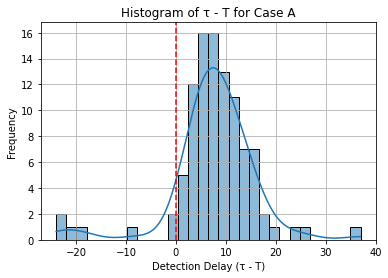

B - Mean: 12.56, Min: 2, Max: 41


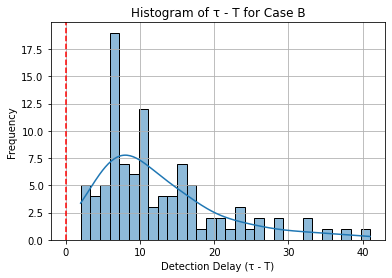

C - Mean: 9.22, Min: -40, Max: 45


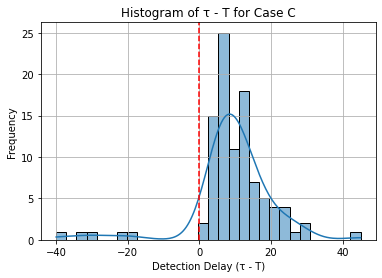

D - Mean: 20.86, Min: 1, Max: 75


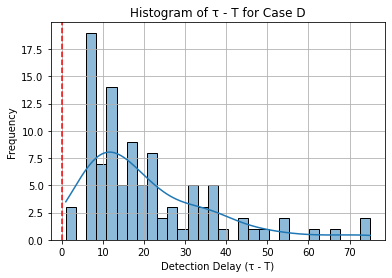

In [5]:
evaluate_and_plot_histogram('A')  # Oracle
evaluate_and_plot_histogram('B')  # Misspecified
evaluate_and_plot_histogram('C')
evaluate_and_plot_histogram('D')


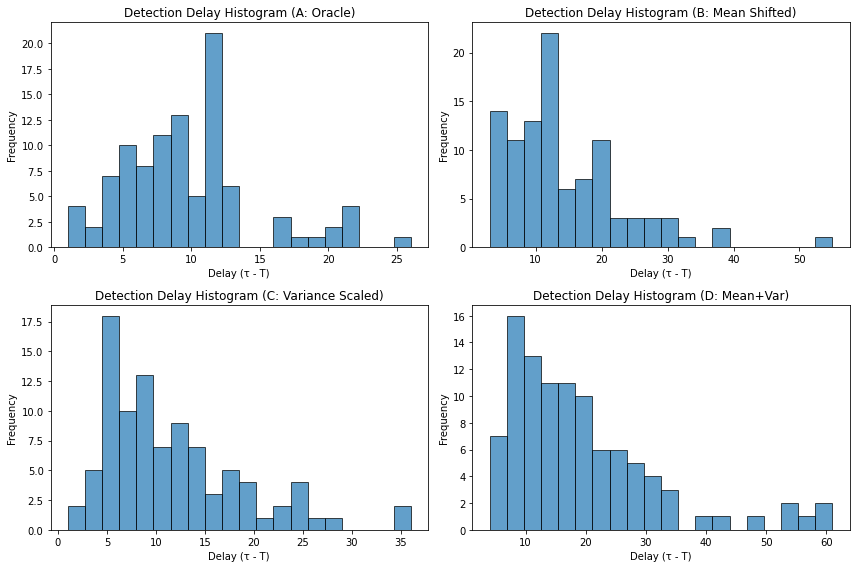

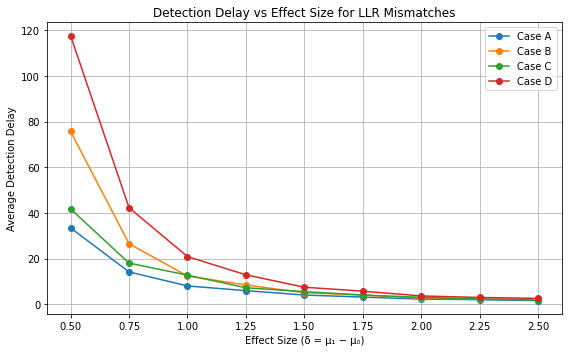

In [6]:
# 1. Detection delay histograms per mismatch case (fixed delta)
def delay_histograms(delta=1.0, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    all_delays = {}
    for case in ['A', 'B', 'C', 'D']:
        f0_m, f1_m = make_llr_pdfs(case, delta)
        detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)
        delays = []

        for _ in range(num_trials):
            stream = np.concatenate([
                np.random.normal(0, 1, changepoint),
                np.random.normal(delta, 1, stream_length - changepoint)
            ])
            _, _, tau = detector.run(stream)
            if tau is not None and tau > changepoint:
                delays.append(tau - changepoint)

        all_delays[case] = delays

    return all_delays

# 2. Delay vs delta for all cases
def delay_vs_delta(delta_vals, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    delays_by_case = {c: [] for c in ['A', 'B', 'C', 'D']}

    for delta in delta_vals:
        for case in ['A', 'B', 'C', 'D']:
            f0_m, f1_m = make_llr_pdfs(case, delta)
            detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)
            delays = []

            for _ in range(num_trials):
                stream = np.concatenate([
                    np.random.normal(0, 1, changepoint),
                    np.random.normal(delta, 1, stream_length - changepoint)
                ])
                _, _, tau = detector.run(stream)
                if tau is not None and tau > changepoint:
                    delays.append(tau - changepoint)

            avg = np.mean(delays) if delays else np.nan
            delays_by_case[case].append(avg)

    return delays_by_case

# Run both experiments
delta_vals = np.linspace(0.5, 2.5, 9)
delay_vs_d = delay_vs_delta(delta_vals)
delay_hists = delay_histograms()

# Plot 1: Histograms
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs = axs.flatten()
labels = ['A: Oracle', 'B: Mean Shifted', 'C: Variance Scaled', 'D: Mean+Var']
for i, case in enumerate(['A', 'B', 'C', 'D']):
    axs[i].hist(delay_hists[case], bins=20, edgecolor='black', alpha=0.7)
    axs[i].set_title(f'Detection Delay Histogram ({labels[i]})')
    axs[i].set_xlabel("Delay (τ - T)")
    axs[i].set_ylabel("Frequency")
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/LLR_misspec_effects_histograms.png", dpi=300, bbox_inches='tight')
plt.show()

# Plot 2: Delay vs Delta
plt.figure(figsize=(8, 5))
for case in ['A', 'B', 'C', 'D']:
    plt.plot(delta_vals, delay_vs_d[case], marker='o', label=f'Case {case}')
plt.xlabel("Effect Size (δ = μ₁ − μ₀)")
plt.ylabel("Average Detection Delay")
plt.title("Detection Delay vs Effect Size for LLR Mismatches")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/LLR_misspec_effects_effect_size.png", dpi=300, bbox_inches='tight')
plt.show()

In [7]:
def delay_histograms_all_tau(delta=1.0, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    all_delays = {}
    for case in ['A', 'B', 'C', 'D']:
        f0_m, f1_m = make_llr_pdfs(case, delta)
        detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)
        delays = []

        for _ in range(num_trials):
            stream = np.concatenate([
                np.random.normal(0, 1, changepoint),
                np.random.normal(delta, 1, stream_length - changepoint)
            ])
            _, _, tau = detector.run(stream)
            if tau is not None:
                delays.append(tau - changepoint)  # allow negative delays

        all_delays[case] = delays

    return all_delays

In [8]:
def delay_vs_delta_all_tau(delta_vals, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    delays_by_case = {c: [] for c in ['A', 'B', 'C', 'D']}

    for delta in delta_vals:
        for case in ['A', 'B', 'C', 'D']:
            f0_m, f1_m = make_llr_pdfs(case, delta)
            detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)
            delays = []

            for _ in range(num_trials):
                stream = np.concatenate([
                    np.random.normal(0, 1, changepoint),
                    np.random.normal(delta, 1, stream_length - changepoint)
                ])
                _, _, tau = detector.run(stream)
                if tau is not None:
                    delays.append(tau - changepoint)

            avg = np.mean(delays) if delays else np.nan
            delays_by_case[case].append(avg)

    return delays_by_case


In [9]:
delta_vals = np.linspace(0.5, 2.5, 9)
delay_vs_d_all = delay_vs_delta_all_tau(delta_vals)
delay_hists_all = delay_histograms_all_tau()


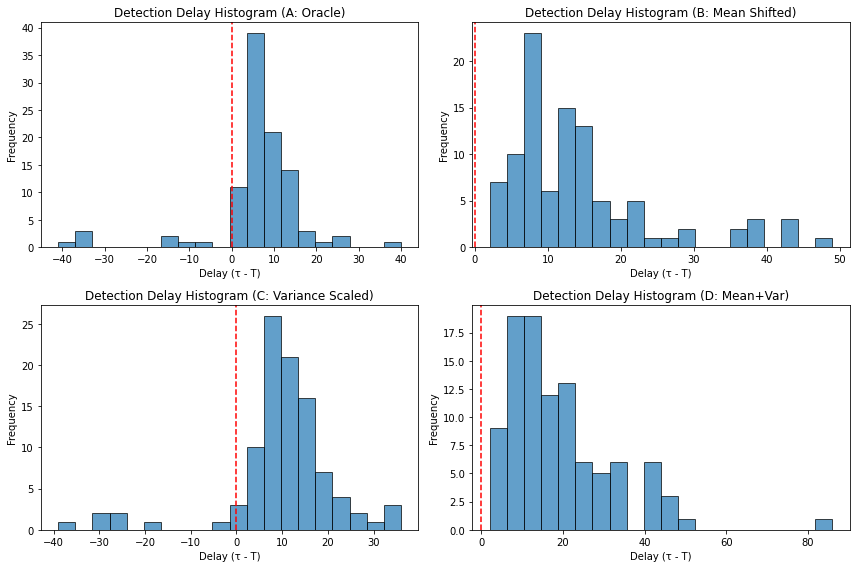

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs = axs.flatten()
labels = ['A: Oracle', 'B: Mean Shifted', 'C: Variance Scaled', 'D: Mean+Var']
for i, case in enumerate(['A', 'B', 'C', 'D']):
    axs[i].hist(delay_hists_all[case], bins=20, edgecolor='black', alpha=0.7)
    axs[i].axvline(0, color='red', linestyle='--')  # τ = T line
    axs[i].set_title(f'Detection Delay Histogram ({labels[i]})')
    axs[i].set_xlabel("Delay (τ - T)")
    axs[i].set_ylabel("Frequency")
plt.tight_layout()
plt.show()


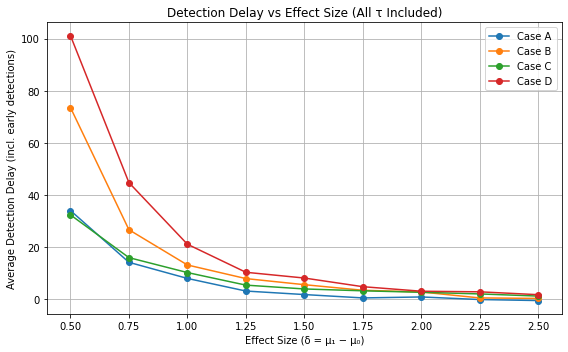

In [11]:
plt.figure(figsize=(8, 5))
for case in ['A', 'B', 'C', 'D']:
    plt.plot(delta_vals, delay_vs_d_all[case], marker='o', label=f'Case {case}')
plt.xlabel("Effect Size (δ = μ₁ − μ₀)")
plt.ylabel("Average Detection Delay (incl. early detections)")
plt.title("Detection Delay vs Effect Size (All τ Included)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
